# 03 — Fine-tuning da StarNet-S4 (baseline)

Treina a StarNet-S4 (MA et al., 2024) a partir dos pesos ImageNet-1K oficiais no dataset
`cerrado_df_v1`, com `configs/experiments/starnet_s4_ft.yaml`, **idêntica** à do GmNet-S3
exceto pelo modelo (regra 7; conferido por `tests/test_configs.py`).

Desenho (b): GmNet-S3 completo vs. StarNet-S4. As arquiteturas diferem em mais do que o
gating (larguras/profundidades, BN e *layer scale*, receita de treino no ImageNet), então a
comparação **não isola** o efeito do gating.

**Antes**: rode o `00_setup_colab.ipynb` no mesmo ambiente. Use um ambiente com **GPU**.

- Pesos: baixados do release oficial para `<drive_root>/pretrained/` se não existirem, com
  SHA-256 conferido, seguidos de um teste de sanidade em 200 imagens do ImageNet.
- Checkpoints e resultados: como no notebook 02, em `<drive_root>/checkpoints|results/starnet_s4_ft/seed_<n>/`.
- Resultados para o artigo: só no modo `git`, sem alterações não commitadas.

In [1]:
CONFIG = "configs/experiments/starnet_s4_ft.yaml"
RUN_TESTS = True  # roda a suíte de testes (incluindo os de PyTorch) antes de treinar

## 1. Ambiente

In [2]:
import importlib
import sys
from pathlib import Path

import torch
import yaml

REPO_DIR = Path("/content/ProjetoFinalRNAP_UnB2026")
assert REPO_DIR.exists(), "Rode antes o 00_setup_colab.ipynb neste ambiente."

# O kernel em execução não lê o .pth da instalação editável (ver notebook 00).
SRC_DIR = str(REPO_DIR / "src")
if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)
importlib.invalidate_caches()

from cerrado_flora.utils import run_metadata

paths = yaml.safe_load((REPO_DIR / "configs/paths.yaml").read_text())
cfg = yaml.safe_load((REPO_DIR / CONFIG).read_text())
pretrained_cfg = yaml.safe_load((REPO_DIR / "configs/pretrained.yaml").read_text())

drive_root = Path(paths["drive_root"])
assert drive_root.exists(), "Google Drive não montado (seção 1 do notebook 00)."
images_root = Path(paths["local_cache"]) / cfg["dataset"]["name"]
assert (images_root / "images").exists(), "Dataset ausente: rode a seção 5 do notebook 00."
manifest = REPO_DIR / cfg["dataset"]["manifest"]

meta = run_metadata.collect(REPO_DIR)
print("commit:", meta["git_commit"], "| alterações não commitadas:", meta["git_dirty"])
if meta["git_commit"] is None or meta["git_dirty"]:
    print("AVISO: sem commit limpo; estes resultados não devem entrar no artigo (modo git).")
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NENHUMA")
assert torch.cuda.is_available(), "Selecione um ambiente com GPU."

commit: b993e6e4d68375fcb2360d467b72eb0f2c29720d | alterações não commitadas: False
GPU: Tesla T4


## 2. Testes

In [ ]:
import subprocess

if RUN_TESTS:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pytest"], check=True)
    # -rfEs: resumo com falhas (f), erros (E) e testes pulados (s);
    # --tb=short: traceback curto de cada falha. Saída completa, sem cortes.
    r = subprocess.run([sys.executable, "-m", "pytest", "-q", "-rfEs", "--tb=short", "tests"],
                       cwd=REPO_DIR, capture_output=True, text=True)
    print(r.stdout)
    if r.stderr:
        print(r.stderr)
    assert r.returncode == 0, "testes falharam (ver 'short test summary info' acima)"

## 3. Pesos pré-treinados

In [4]:
from cerrado_flora.data.download import download
from cerrado_flora.data.inaturalist import make_session
from cerrado_flora.models.factory import verify_checkpoint

wcfg = pretrained_cfg[cfg["model"]["pretrained"]]
weights = drive_root / paths["drive_subdirs"]["pretrained"] / wcfg["file"]
if not weights.exists():
    err = download(make_session("cerrado-flora/0.1 (academic research)"), wcfg["url"], weights)
    assert err is None, err
verify_checkpoint(weights, wcfg["sha256"])
print("pesos verificados:", weights)

pesos verificados: /content/drive/MyDrive/ProjetoFinalRNAP_UnB2026/pretrained/starnet_s4.pth.tar


Teste de sanidade: os pesos com a cabeça original de 1000 classes em 200 imagens do ImageNet
(mesmo protocolo usado para o GmNet-S3, que deu 86,5% de top-1). Pesos carregados na
arquitetura errada dão ~0%.

In [5]:
from cerrado_flora.evaluation.imagenet_sanity import download_sample, imagenet_topk
from cerrado_flora.models.factory import build_model

samples = download_sample("/content/cache/imagenet_sample")
sanity = imagenet_topk(build_model(cfg["model"], 1000, weights), samples, torch.device("cuda"))
print("ImageNet (amostra):", sanity)
assert sanity["top1"] > 0.5, "pesos possivelmente carregados de forma incorreta"

ImageNet (amostra): {'top1': 0.945, 'top5': 0.995, 'n': 200}


## 4. Treino e avaliação

In [6]:
from cerrado_flora.training.train import run_experiment

exp = cfg["name"]
results = {}
for seed in cfg["seeds"]:
    results[seed] = run_experiment(
        cfg, seed, manifest, images_root, weights,
        ckpt_dir=drive_root / paths["drive_subdirs"]["checkpoints"] / exp / f"seed_{seed}",
        results_dir=drive_root / paths["drive_subdirs"]["results"] / exp / f"seed_{seed}",
    )

/content/ProjetoFinalRNAP_UnB2026/src/cerrado_flora/training/train.py:153: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


época 1/50  loss 3.358  val top1 0.220  val macro-F1 0.205  (38s)
época 2/50  loss 2.637  val top1 0.499  val macro-F1 0.501  (34s)
época 3/50  loss 1.725  val top1 0.649  val macro-F1 0.671  (39s)
época 4/50  loss 1.288  val top1 0.708  val macro-F1 0.734  (37s)
época 5/50  loss 1.125  val top1 0.707  val macro-F1 0.733  (39s)
época 6/50  loss 1.035  val top1 0.710  val macro-F1 0.724  (36s)
época 7/50  loss 0.947  val top1 0.745  val macro-F1 0.767  (38s)
época 8/50  loss 0.889  val top1 0.774  val macro-F1 0.782  (38s)
época 9/50  loss 0.823  val top1 0.761  val macro-F1 0.787  (39s)
época 10/50  loss 0.822  val top1 0.752  val macro-F1 0.778  (40s)
época 11/50  loss 0.779  val top1 0.783  val macro-F1 0.798  (37s)
época 12/50  loss 0.768  val top1 0.771  val macro-F1 0.785  (39s)
época 13/50  loss 0.777  val top1 0.747  val macro-F1 0.774  (36s)
época 14/50  loss 0.759  val top1 0.779  val macro-F1 0.796  (38s)
época 15/50  loss 0.735  val top1 0.778  val macro-F1 0.797  (37s)
époc

## 5. Resultados

In [7]:
import pandas as pd

rows = []
for seed, r in results.items():
    for split in ("val", "test"):
        for level in ("photo", "observation"):
            rows.append({"seed": seed, "divisao": split, "nivel": level,
                         **{k: r[split][level][k] for k in ("top1", "macro_f1", "balanced_accuracy", "n")},
                         "melhor_epoca": r["best_epoch"]})
pd.DataFrame(rows).round(4)

,seed,divisao,nivel,top1,macro_f1,balanced_accuracy,n,melhor_epoca
0,2026,val,photo,0.8401,0.8558,0.8574,982,39
1,2026,val,observation,0.9284,0.9347,0.9339,377,39
2,2026,test,photo,0.8253,0.8425,0.8356,956,39
3,2026,test,observation,0.9257,0.9253,0.9246,377,39


In [ ]:
# Média ± desvio padrão entre as sementes concluídas (melhor_epoca conta a partir de 0)
summary = (pd.DataFrame(rows).groupby(["divisao", "nivel"])[["top1", "macro_f1", "balanced_accuracy"]]
           .agg(["mean", "std"]).round(4))
print(f"{len(results)} sementes: {sorted(results)}")
summary

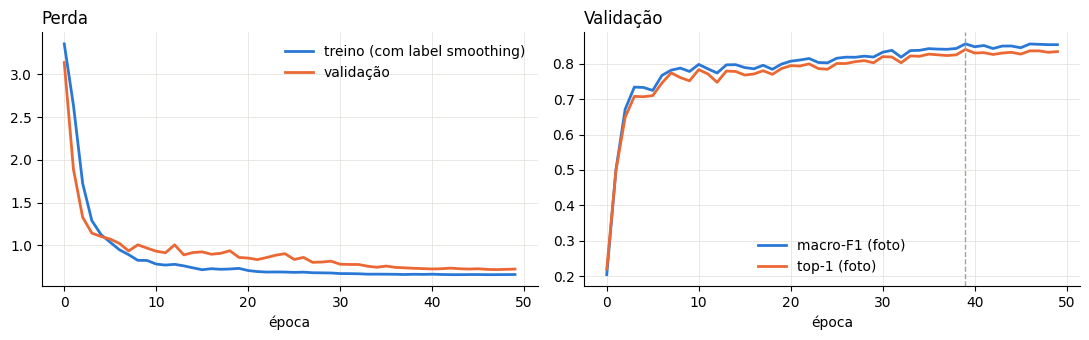

tempo médio por época: 37s


In [8]:
import matplotlib.pyplot as plt

seed = cfg["seeds"][0]
res_dir = drive_root / paths["drive_subdirs"]["results"] / exp / f"seed_{seed}"
h = pd.read_csv(res_dir / "history.csv")
blue, orange = "#2a78d6", "#eb6834"  # paleta categórica validada

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
a1.plot(h["epoch"], h["train_loss"], color=blue, lw=2, label="treino (com label smoothing)")
a1.plot(h["epoch"], h["val_loss"], color=orange, lw=2, label="validação")
a1.set_title("Perda", loc="left")
a2.plot(h["epoch"], h["val_macro_f1"], color=blue, lw=2, label="macro-F1 (foto)")
a2.plot(h["epoch"], h["val_top1"], color=orange, lw=2, label="top-1 (foto)")
a2.axvline(results[seed]["best_epoch"], color="#a3a29d", lw=1, ls="--")
a2.set_title("Validação", loc="left")
for a in (a1, a2):
    a.set_xlabel("época")
    a.grid(color="#e5e4e0", lw=0.6)
    a.set_axisbelow(True)
    for side in ("top", "right"):
        a.spines[side].set_visible(False)
    a.legend(frameon=False)
plt.tight_layout()
plt.show()
print(f"tempo médio por época: {h['epoch_time_s'].mean():.0f}s")

F1 por classe no teste (por foto), da pior para a melhor:

In [9]:
species = pd.read_csv(manifest.parent / "species.csv").dropna(subset=["class_index"])
names = species.set_index(species["class_index"].astype(int))["scientific_name"]
pc = pd.read_csv(res_dir / "per_class_test.csv", index_col="class_index")
pc.insert(0, "especie", names)
pc.sort_values("f1").round(3)

,especie,precision,recall,f1,support
class_index,,,,,
21,Qualea parviflora,0.641,0.521,0.575,48
8,Eugenia dysenterica,0.641,0.641,0.641,39
4,Copaifera langsdorffii,0.609,0.737,0.667,19
20,Qualea grandiflora,0.714,0.635,0.672,63
25,Syagrus flexuosa,0.846,0.579,0.688,19
3,Caryocar brasiliense,0.653,0.855,0.740,55
6,Eriotheca pubescens,0.769,0.769,0.769,39
12,Kielmeyera coriacea,0.810,0.756,0.782,45
28,Vochysia thyrsoidea,0.760,0.864,0.809,22
